# Solution: Mini-Project 1 — Sales Analysis

**Dataset:** `sales_data.csv` (2024 orders from a retail business with outlets across India)
**Objective:** analyse sales performance and find insights the business can act on.

**Deliverable:** this notebook, completed. Each task needs code, its output and a short markdown explanation.
It must run top to bottom (**Kernel → Restart & Run All**). Finish with a written *Insights & Recommendations* section.

| Section | Tasks |
|---|---|
| A. Data preparation | 1 – 3 |
| B. Performance overview | 4 |
| C. Revenue trends | 5 |
| D. Products and categories | 6 – 7 |
| E. Regional comparison | 8 |
| F. Monthly sales visualisation | 9 |
| G. Insights & recommendations | 10 |

**Student name:** _____________ &nbsp;&nbsp; **Roll no.:** _____________ &nbsp;&nbsp; **Section:** ___

> **Instructor solution.** Attempt the exercises yourself before reading this. Your answers may differ in method and still be correct.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "../../datasets/"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4.5)
pd.set_option("display.float_format", "{:,.2f}".format)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## A. Data preparation

### Exercise 1 — Load and inspect

Load the data. Report the number of rows and columns, the data types, and a list of every data-quality problem you can find.

In [2]:
raw = pd.read_csv(DATA_DIR + "sales_data.csv")
print("Shape:", raw.shape)
raw.info()

print("\nMissing values:\n", raw.isna().sum()[raw.isna().sum() > 0])
print("\nExact duplicate rows:", raw.duplicated().sum())
print("Region labels:", sorted(raw["Region"].unique()))
print("Prices stored as text, e.g.:", raw.loc[raw["Unit_Price"].astype(str).str.startswith("Rs."), "Unit_Price"].head(3).tolist())

Shape: (1215, 11)
<class 'pandas.DataFrame'>
RangeIndex: 1215 entries, 0 to 1214
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          1215 non-null   str    
 1   Order_Date        1215 non-null   str    
 2   Region            1215 non-null   str    
 3   City              1215 non-null   str    
 4   Customer_Segment  1205 non-null   str    
 5   Category          1215 non-null   str    
 6   Product           1215 non-null   str    
 7   Quantity          1195 non-null   float64
 8   Unit_Price        1203 non-null   str    
 9   Discount          1215 non-null   float64
 10  Payment_Mode      1215 non-null   str    
dtypes: float64(2), str(9)
memory usage: 104.5 KB

Missing values:
 Customer_Segment    10
Quantity            20
Unit_Price          12
dtype: int64

Exact duplicate rows: 15
Region labels: [' North', ' South', ' West', 'CENTRAL', 'Central', 'Central ', 'East', 'East ', 'NO

> **Note:** Problems found: 15 duplicate rows; inconsistent `Region` labels; `Unit_Price` stored as text because some values have an `Rs.` prefix; missing `Quantity`, `Unit_Price` and `Customer_Segment`; `Order_Date` stored as text.

### Exercise 2 — Clean the data

Fix every problem you listed in Task 1. For each fix, print a check that proves it worked. In markdown, explain how you filled each missing value and why.

In [3]:
sales = raw.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", len(raw) - len(sales))

sales["Region"] = sales["Region"].str.strip().str.title()
print("Regions:", sorted(sales["Region"].unique()))

sales["Unit_Price"] = pd.to_numeric(
    sales["Unit_Price"].astype(str).str.replace("Rs.", "", regex=False).str.strip(), errors="coerce")
print("Unit_Price dtype:", sales["Unit_Price"].dtype)

for col in ["Unit_Price", "Quantity"]:
    sales[col] = sales[col].fillna(sales.groupby("Product")[col].transform("median"))
sales["Quantity"] = sales["Quantity"].round().astype(int)
sales["Customer_Segment"] = sales["Customer_Segment"].fillna("Unknown")
sales["Order_Date"] = pd.to_datetime(sales["Order_Date"])

print("Missing values remaining:", sales.isna().sum().sum())
print("Order_ID unique:", sales["Order_ID"].is_unique)

Duplicates removed: 15
Regions: ['Central', 'East', 'North', 'South', 'West']
Unit_Price dtype: float64
Missing values remaining: 0
Order_ID unique: True


> **Note:** Missing prices and quantities are filled with the **median for the same product**, because prices differ hugely between products (a pen against a laptop). The median is not distorted by unusual orders. A missing segment is labelled `Unknown` because guessing a customer's type would invent data.

### Exercise 3 — Feature engineering

Add the columns `Revenue` (= Quantity × Unit_Price × (1 − Discount)), `Gross_Value` (before discount), `Discount_Amount`, `Month`, `Month_Name` and `Quarter`.

In [4]:
sales["Gross_Value"] = sales["Quantity"] * sales["Unit_Price"]
sales["Revenue"] = (sales["Gross_Value"] * (1 - sales["Discount"])).round(2)
sales["Discount_Amount"] = sales["Gross_Value"] - sales["Revenue"]
sales["Month"] = sales["Order_Date"].dt.month
sales["Month_Name"] = pd.Categorical(sales["Order_Date"].dt.strftime("%b"), categories=MONTHS, ordered=True)
sales["Quarter"] = "Q" + sales["Order_Date"].dt.quarter.astype(str)
sales.head()

,Order_ID,Order_Date,Region,City,Customer_Segment,Category,Product,Quantity,Unit_Price,Discount,Payment_Mode,Gross_Value,Revenue,Discount_Amount,Month,Month_Name,Quarter
0,ORD10069,2024-01-01,North,Delhi,Consumer,Clothing,Jeans,2,"1,412.69",0.05,Credit Card,"2,825.38","2,684.11",141.27,1,Jan,Q1
1,ORD10125,2024-01-02,North,Chandigarh,Consumer,Electronics,Headphones,1,"2,362.65",0.15,Cash,"2,362.65","2,008.25",354.40,1,Jan,Q1
2,ORD11101,2024-01-02,South,Hyderabad,Corporate,Electronics,Smartphone,3,"17,702.51",0.05,Credit Card,"53,107.53","50,452.15","2,655.38",1,Jan,Q1
3,ORD10395,2024-01-03,Central,Nagpur,Corporate,Electronics,Headphones,8,"2,368.19",0.05,Debit Card,"18,945.52","17,998.24",947.28,1,Jan,Q1
4,ORD11161,2024-01-03,East,Bhubaneswar,Corporate,Electronics,Smartphone,2,"16,847.36",0.00,UPI,"33,694.72","33,694.72",0.00,1,Jan,Q1


## B. Performance overview

### Exercise 4 — Key performance indicators (KPIs)

Calculate and display: total revenue (lakh), total orders, total units, average order value (AOV), total discount given (lakh) and the average discount rate weighted by value.

In [5]:
kpi = pd.Series({
    "Total revenue (Rs. lakh)": sales["Revenue"].sum() / 1e5,
    "Total orders": len(sales),
    "Total units sold": sales["Quantity"].sum(),
    "Average order value (Rs.)": sales["Revenue"].mean(),
    "Discount given (Rs. lakh)": sales["Discount_Amount"].sum() / 1e5,
    "Effective discount rate (%)": sales["Discount_Amount"].sum() / sales["Gross_Value"].sum() * 100,
})
kpi.to_frame("Value").round(2)

,Value
Total revenue (Rs. lakh),219.01
Total orders,"1,200.00"
Total units sold,"4,727.00"
Average order value (Rs.),"18,250.63"
Discount given (Rs. lakh),15.31
Effective discount rate (%),6.54


## C. Revenue trends

### Exercise 5 — Monthly revenue trend and growth

Compute monthly revenue and month-on-month (MoM) growth %. Plot monthly revenue as a line chart and mark the best and worst months. Which quarter was strongest?

,Orders,Revenue_Lakh,MoM_Growth_Pct
Month_Name,,,
Jan,83,15.40,NaN
Feb,104,18.90,23.00
Mar,91,15.00,-20.80
Apr,86,17.70,18.10
May,77,14.40,-18.90
Jun,78,14.00,-2.10
Jul,91,13.50,-4.20
Aug,82,15.70,17.00
Sep,108,16.50,5.00


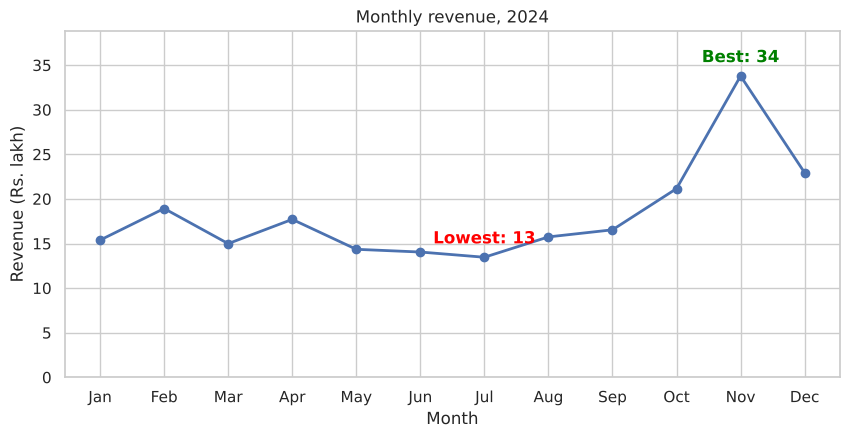

Revenue by quarter (lakh):
 Quarter
Q1   49.30
Q2   46.10
Q3   45.70
Q4   77.90
Name: Revenue, dtype: float64
Strongest quarter: Q4


In [6]:
monthly = sales.groupby("Month_Name", observed=True).agg(Revenue=("Revenue", "sum"), Orders=("Order_ID", "count"))
monthly["Revenue_Lakh"] = monthly["Revenue"] / 1e5
monthly["MoM_Growth_Pct"] = monthly["Revenue"].pct_change() * 100
display(monthly[["Orders", "Revenue_Lakh", "MoM_Growth_Pct"]].round(1))

fig, ax = plt.subplots()
ax.plot(monthly.index.astype(str), monthly["Revenue_Lakh"], marker="o", linewidth=2)
best, worst = monthly["Revenue_Lakh"].idxmax(), monthly["Revenue_Lakh"].idxmin()
for m, label, colour in [(best, "Best", "green"), (worst, "Lowest", "red")]:
    y = monthly.loc[m, "Revenue_Lakh"]
    ax.annotate(f"{label}: {y:.0f}", (str(m), y), textcoords="offset points", xytext=(0, 10),
                ha="center", color=colour, fontweight="bold")
ax.set(title="Monthly revenue, 2024", xlabel="Month", ylabel="Revenue (Rs. lakh)")
ax.set_ylim(0, monthly["Revenue_Lakh"].max() * 1.15)
plt.show()

quarterly = sales.groupby("Quarter")["Revenue"].sum() / 1e5
print("Revenue by quarter (lakh):\n", quarterly.round(1))
print("Strongest quarter:", quarterly.idxmax())

## D. Products and categories

### Exercise 6 — Top-performing products

Find the top 10 products by revenue and the top 10 by units sold. Are they the same products? Show the revenue ranking as a horizontal bar chart coloured by category.

,Product,Category,Revenue_Lakh,Units
4,Laptop,Electronics,71.80,148
13,Sofa,Furniture,28.70,95
11,Smartphone,Electronics,26.90,160
5,Monitor,Electronics,13.40,134
10,Saree,Clothing,13.00,393
1,Headphones,Electronics,12.40,522
2,Jacket,Clothing,8.90,341
12,Smartwatch,Electronics,8.00,133
15,Study Table,Furniture,7.10,86
7,Office Chair,Furniture,6.10,87


Top 10 by units: ['Headphones', 'Pen Set', 'Whiteboard', 'Saree', 'Stapler', 'Printer Ink', 'Jacket', 'Notebook Pack', 'Jeans', 'T-Shirt']
In both lists: ['Headphones', 'Jacket', 'Saree']


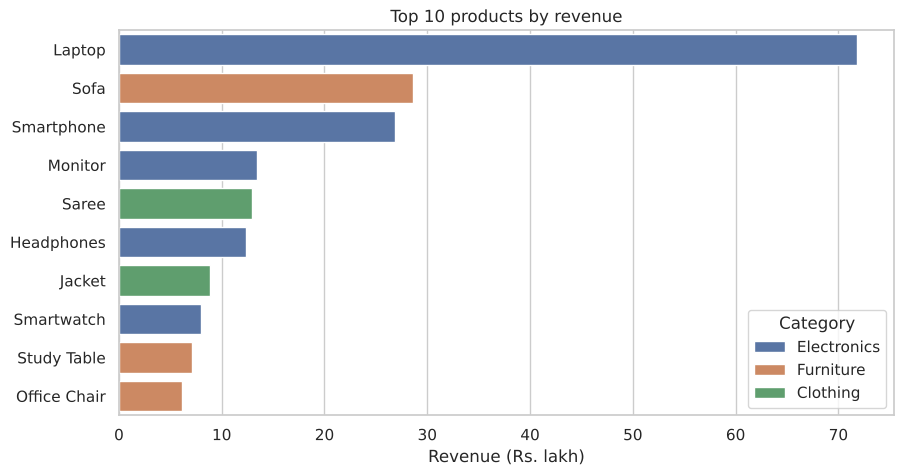

In [7]:
prod = (sales.groupby(["Product", "Category"], as_index=False)
        .agg(Revenue=("Revenue", "sum"), Units=("Quantity", "sum"), Orders=("Order_ID", "count")))
prod["Revenue_Lakh"] = prod["Revenue"] / 1e5
top_rev = prod.nlargest(10, "Revenue_Lakh")
top_units = prod.nlargest(10, "Units")
display(top_rev[["Product", "Category", "Revenue_Lakh", "Units"]].round(1))
print("Top 10 by units:", top_units["Product"].tolist())
print("In both lists:", sorted(set(top_rev["Product"]) & set(top_units["Product"])))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top_rev, y="Product", x="Revenue_Lakh", hue="Category", dodge=False, ax=ax)
ax.set(title="Top 10 products by revenue", xlabel="Revenue (Rs. lakh)", ylabel="")
plt.show()

> **Note:** The two lists are different. Cheap items such as pen sets, staplers and whiteboards are near the top for units but earn little. Laptops and sofas sell few units but dominate revenue. Volume and value are separate measures of success.

### Exercise 7 — Category performance

For each category, report revenue, share of revenue, units, AOV and effective discount rate. Which category depends most on discounts?

In [8]:
cat = sales.groupby("Category").agg(
    Revenue=("Revenue", "sum"), Units=("Quantity", "sum"), Orders=("Order_ID", "count"),
    AOV=("Revenue", "mean"), Gross=("Gross_Value", "sum"), Disc=("Discount_Amount", "sum"))
cat["Revenue_Share_Pct"] = cat["Revenue"] / cat["Revenue"].sum() * 100
cat["Effective_Discount_Pct"] = cat["Disc"] / cat["Gross"] * 100
cat["Revenue_Lakh"] = cat["Revenue"] / 1e5
display(cat[["Revenue_Lakh", "Revenue_Share_Pct", "Units", "Orders", "AOV", "Effective_Discount_Pct"]]
        .sort_values("Revenue_Lakh", ascending=False).round(1))

,Revenue_Lakh,Revenue_Share_Pct,Units,Orders,AOV,Effective_Discount_Pct
Category,,,,,,
Electronics,132.50,60.50,1097,384,"34,495.90",6.50
Furniture,46.90,21.40,364,186,"25,190.70",6.50
Clothing,27.90,12.70,1319,251,"11,112.60",6.40
Office Supplies,11.80,5.40,1947,379,"3,112.40",7.30


## E. Regional comparison

### Exercise 8 — Regional performance

Compare regions on revenue, orders and AOV. Draw a heatmap of revenue by region × category. For each region, find its best-selling city.

,Revenue_Lakh,Orders,AOV,Share_Pct
Region,,,,
South,62.80,351,"17,890.50",28.70
West,53.50,271,"19,730.90",24.40
North,46.50,253,"18,375.80",21.20
East,35.70,196,"18,233.20",16.30
Central,20.50,129,"15,901.70",9.40


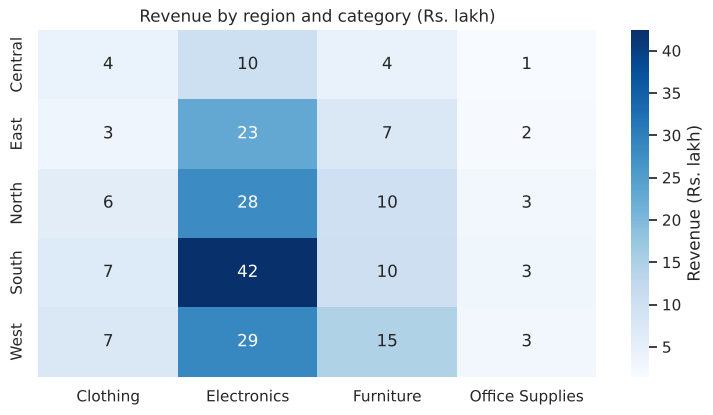

,Region,City,Revenue_Lakh
2,Central,Nagpur,8.00
4,East,Kolkata,14.80
6,North,Chandigarh,17.60
11,South,Hyderabad,22.20
14,West,Pune,20.60


In [9]:
reg = sales.groupby("Region").agg(Revenue_Lakh=("Revenue", lambda s: s.sum() / 1e5),
                                  Orders=("Order_ID", "count"), AOV=("Revenue", "mean"))
reg["Share_Pct"] = reg["Revenue_Lakh"] / reg["Revenue_Lakh"].sum() * 100
display(reg.sort_values("Revenue_Lakh", ascending=False).round(1))

heat = sales.pivot_table(index="Region", columns="Category", values="Revenue", aggfunc="sum") / 1e5
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "Revenue (Rs. lakh)"}, ax=ax)
ax.set(title="Revenue by region and category (Rs. lakh)", xlabel="", ylabel="")
plt.show()

city = sales.groupby(["Region", "City"], as_index=False)["Revenue"].sum()
best_city = city.loc[city.groupby("Region")["Revenue"].idxmax()]
best_city.assign(Revenue_Lakh=best_city["Revenue"] / 1e5)[["Region", "City", "Revenue_Lakh"]].round(1)

## F. Monthly sales visualisation

### Exercise 9 — Monthly sales by category and region

Create (a) a stacked bar chart of monthly revenue by category and (b) a month × region heatmap of order counts. Describe any seasonal pattern you see.

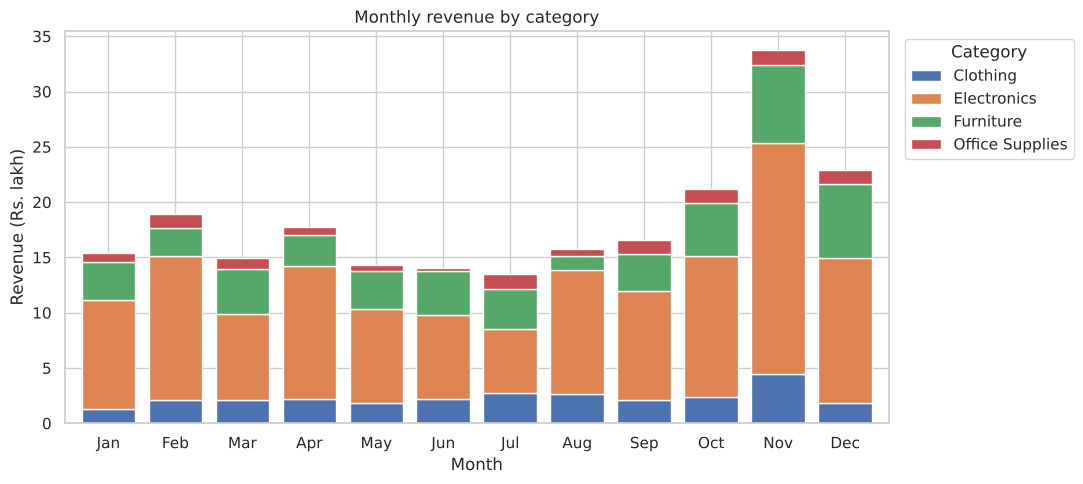

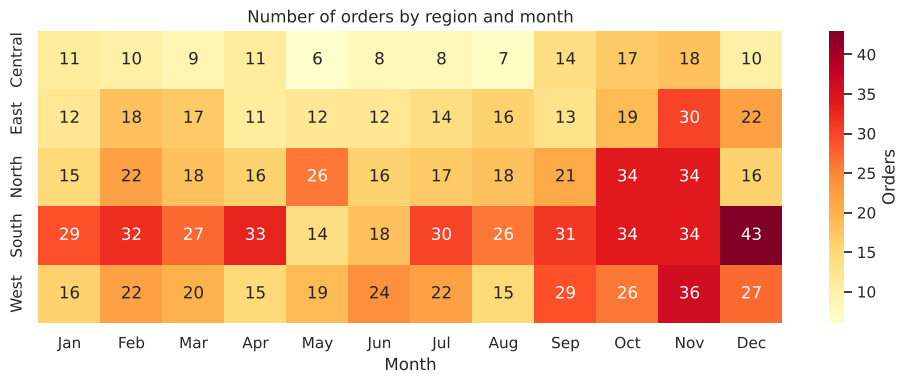

In [10]:
mc = sales.pivot_table(index="Month_Name", columns="Category", values="Revenue", aggfunc="sum", observed=True) / 1e5
ax = mc.plot(kind="bar", stacked=True, figsize=(11, 5), width=0.8)
ax.set(title="Monthly revenue by category", xlabel="Month", ylabel="Revenue (Rs. lakh)")
ax.legend(title="Category", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

mr = sales.pivot_table(index="Region", columns="Month_Name", values="Order_ID", aggfunc="count", observed=True)
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(mr, annot=True, fmt="d", cmap="YlOrRd", cbar_kws={"label": "Orders"}, ax=ax)
ax.set(title="Number of orders by region and month", xlabel="Month", ylabel="")
plt.show()

> **Note:** Orders and revenue rise clearly in **October–November**, the Dussehra–Diwali festive season, across all regions. Mid-year (May–July) is the quietest period.

## G. Insights & recommendations

### Exercise 10 — Insights and recommendations

Write **at least five insights**, each supported by a number from your analysis, and **three recommendations**. Mention at least one limitation of the data.

In [11]:
share_top3 = top_rev.head(3)["Revenue"].sum() / sales["Revenue"].sum() * 100
festive = sales[sales["Month"].isin([10, 11])]["Revenue"].sum() / sales["Revenue"].sum() * 100
print(f"Top 3 products' share of revenue: {share_top3:.1f}%")
print(f"Oct + Nov share of annual revenue: {festive:.1f}% (2 of 12 months = 16.7% if spread evenly)")
print(f"Leading region: {reg['Revenue_Lakh'].idxmax()} ({reg['Share_Pct'].max():.1f}% of revenue)")
print(f"Leading category: {cat['Revenue_Share_Pct'].idxmax()} ({cat['Revenue_Share_Pct'].max():.1f}%)")

Top 3 products' share of revenue: 58.1%
Oct + Nov share of annual revenue: 25.1% (2 of 12 months = 16.7% if spread evenly)
Leading region: South (28.7% of revenue)
Leading category: Electronics (60.5%)


> **Note:** **Sample insights** (check the exact figures against your own output)
1. Electronics is the largest category by revenue, driven by laptops and smartphones, even though Office Supplies sells the most units.
2. The top 3 products bring in a large share of revenue, so the business depends heavily on a few expensive items.
3. October and November together earn far more than an even 2-month share, which reflects festive-season demand.
4. South is the strongest region, while Central contributes the least.
5. High-volume products (pen sets, staplers) earn little revenue. Volume and value are different measures of success.

**Recommendations**
1. Build up stock of laptops and smartphones and plan marketing for September, ahead of the festive peak.
2. Bundle fast-moving stationery with higher-value items to raise the average order value.
3. Investigate the Central region: is it under-served (few outlets) or low on demand?

**Limitations:** one year of data only, so we cannot separate seasonality from growth. The data is synthetic and has no cost or profit column, so margins cannot be analysed.